<a href="https://colab.research.google.com/github/bharathy2302/FDS_CASE_STUDY_164/blob/main/FDS164.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fundamentals of Data Science (22CSC59) - Case Studies
**Name:** Bharath Yalamanchili  
**Roll No:** 160124733164  
**Section:** CSE-3
**Year/Semester:** 2026 / V Semester  
**Faculty:** Durga Devi  

## Overview
This notebook presents the execution and analysis of two data science case studies:
1. **Case Study 2:** Clustering Analysis on the EastWestAirlines dataset to identify customer segments using K-Means, Hierarchical, and DBSCAN algorithms.
2. **Case Study 5:** Predictive modeling on Wine Quality to determine if physicochemical laboratory measurements can reliably predict sensory quality assessments using Multiple Linear Regression.

In [2]:
# --- GLOBAL IMPORTS & SETUP ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Clustering & Regression Libraries
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as sch
from scipy.stats import variation

# Visual setup
warnings.filterwarnings("ignore")
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams['figure.figsize'] = (8, 5)

---
# PART 1: CASE STUDY 2 - AIRLINES CLUSTERING ANALYSIS
## 1.1 Problem Statement & Data Loading
**Objective:** Apply unsupervised learning techniques to passenger flight data to discover hidden behavioral clusters and identify frequent flyer archetypes.

In [3]:
# Load the dataset(EastWestAirlines.xlsx)
df_airlines = pd.read_excel('EastWestAirlines.xlsx', sheet_name='data')

# Display dataset dimensions and first few rows
print(f"Dataset Shape: {df_airlines.shape}")
display(df_airlines.head())

Dataset Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


## 1.2 Data Preprocessing & Exploratory Analysis
# Case Study 2: Airlines Clustering Analysis
Here I am looking at the EastWestAirlines dataset to see if we can group passengers based on their flight behavior and find different types of frequent flyers.

Before running any algorithms, I dropped the ID column since it doesn't help with grouping. I also filled in any missing values with the median and scaled the data using StandardScaler. Scaling is super important here because clustering models rely on the distances between data points, and we don't want larger numbers dominating the results.

In [4]:
# Drop the ID column as it holds no behavioral value
if 'ID#' in df_airlines.columns:
    df_airlines = df_airlines.drop('ID#', axis=1)

# Impute any missing values with the median to resist outliers
df_airlines.fillna(df_airlines.median(), inplace=True)

# Standardize the data (Mean=0, Variance=1)
scaler = StandardScaler()
X_air_scaled = scaler.fit_transform(df_airlines)

# Dimensionality reduction for 2D plotting later
pca = PCA(n_components=2)
X_air_pca = pca.fit_transform(X_air_scaled)

print("Preprocessing complete. Data is scaled and ready for clustering.")

Preprocessing complete. Data is scaled and ready for clustering.


## 1.3 Model Implementation: K-Means, Hierarchical, and DBSCAN
### K-Means Optimization
To figure out how many clusters to use for K-Means, I plotted an Elbow Curve to look at the within-cluster sum of squares (WCSS). The curve bends smoothly, but k=4 looks like a good spot to get meaningful groups without making things too complicated. I went ahead and used 4 clusters for both the K-Means and Hierarchical models.

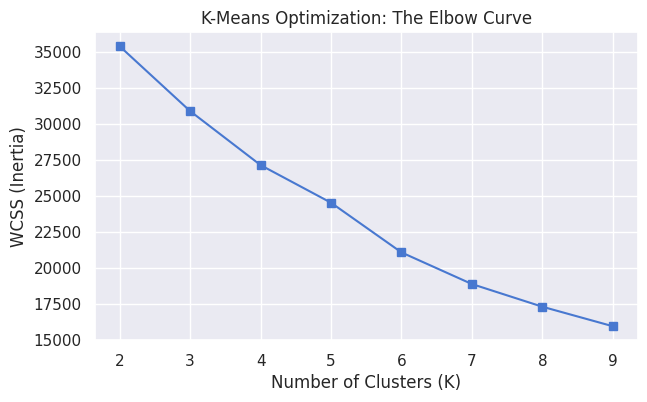

In [5]:
wcss = []
k_range = range(2, 10)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_air_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(k_range, wcss, marker='s', linestyle='-', color='b')
plt.title('K-Means Optimization: The Elbow Curve')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.show()

**Observation:** The elbow bends smoothly, but a K of 4 provides a good balance between segment granularity and computational simplicity. We will proceed with 4 clusters for both K-Means and Hierarchical modeling.

In [6]:
# 1. K-Means (K=4)
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
df_airlines['Cluster_KMeans'] = kmeans_model.fit_predict(X_air_scaled)
sil_kmeans = silhouette_score(X_air_scaled, df_airlines['Cluster_KMeans'])

# 2. Agglomerative Hierarchical (K=4, Ward linkage)
hierarchical_model = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
df_airlines['Cluster_Hierarchical'] = hierarchical_model.fit_predict(X_air_scaled)
sil_hierarchical = silhouette_score(X_air_scaled, df_airlines['Cluster_Hierarchical'])

# 3. DBSCAN (Density-based)
dbscan_model = DBSCAN(eps=2.0, min_samples=5)
df_airlines['Cluster_DBSCAN'] = dbscan_model.fit_predict(X_air_scaled)

# Calculate DBSCAN Silhouette (ignoring the -1 noise cluster)
core_mask = df_airlines['Cluster_DBSCAN'] != -1
if len(set(df_airlines['Cluster_DBSCAN'][core_mask])) > 1:
    sil_dbscan = silhouette_score(X_air_scaled[core_mask], df_airlines['Cluster_DBSCAN'][core_mask])
else:
    sil_dbscan = 0.0

print("--- Silhouette Scores (Clustering Quality) ---")
print(f"K-Means (K=4): {sil_kmeans:.4f}")
print(f"Hierarchical : {sil_hierarchical:.4f}")
print(f"DBSCAN (Core): {sil_dbscan:.4f}")

--- Silhouette Scores (Clustering Quality) ---
K-Means (K=4): 0.3092
Hierarchical : 0.3081
DBSCAN (Core): 0.2805


## 1.4 Visualizing the Clusters
Looking at the cluster means, K-Means split the passengers into a few very clear profiles. The vast majority of people fall into a huge group of casual flyers who don't fly much or earn many rewards. Another interesting group barely flies but earns a ton of miles, likely through airline credit cards. Finally, there's a really small group of elite "road warriors" who fly constantly and have huge mileage balances.

K-Means and Hierarchical clustering gave pretty similar results. DBSCAN acted a bit differently since it's density-based—it mostly just grouped almost everyone into one giant core cluster and marked the extreme high-flyers as noise.

Overall, K-Means gave the most useful breakdown. The airline could use these groups to send targeted credit card offers to the casual flyers and give automatic upgrades to the elite group to keep them happy.

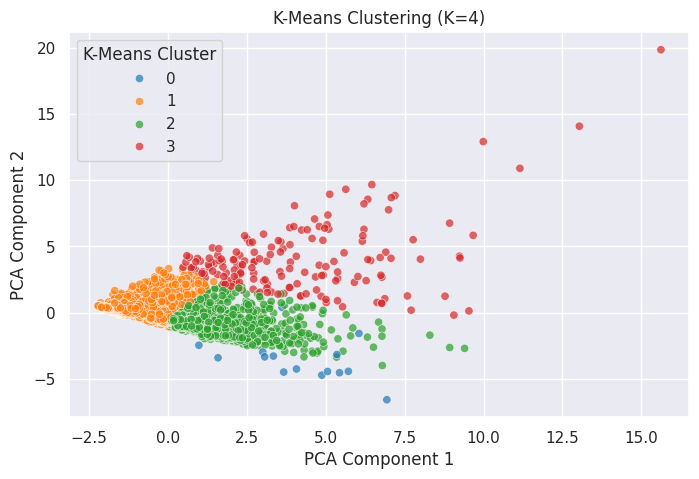

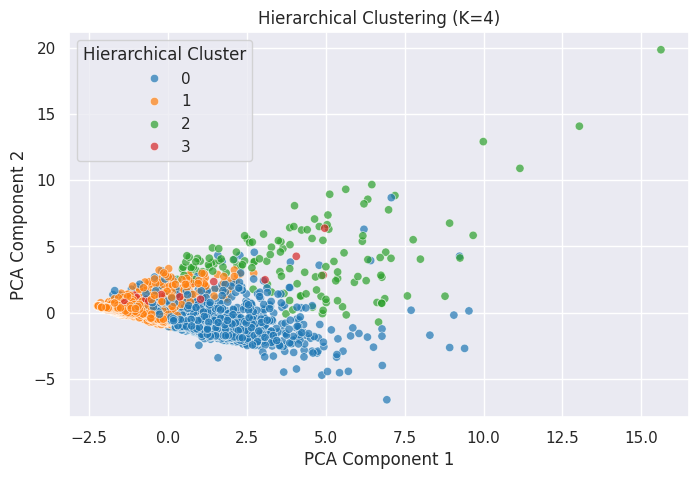

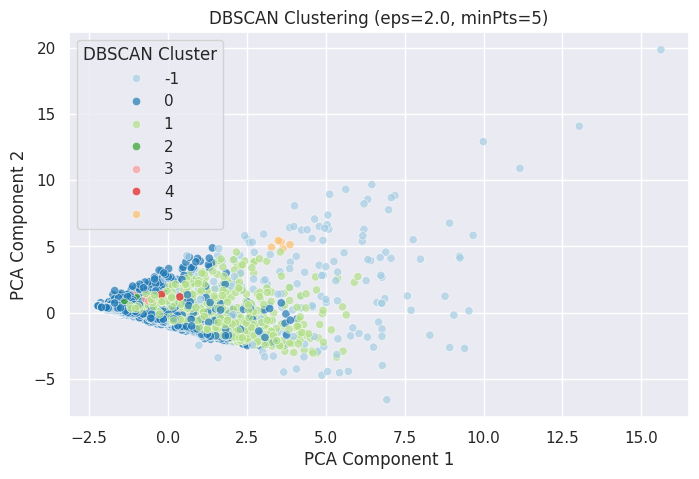

--- K-Means Cluster Centroids (Mean Values) ---


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,Cluster_Hierarchical,Cluster_DBSCAN
Cluster_KMeans,,,,,,,,,,,,,
0,138061.4,78.8,3.5,1.0,4.1,93927.9,28.1,506.7,1.6,4613.9,0.5,0.0,-1.0
1,43793.9,97.4,1.2,1.0,1.0,4700.7,6.9,198.6,0.6,3691.6,0.2,1.0,0.2
2,116817.3,154.8,3.7,1.0,1.0,39216.2,18.8,334.4,1.0,4893.5,0.6,0.1,0.6
3,191573.7,775.9,2.2,1.0,1.0,31412.2,26.8,5365.7,15.6,4665.8,0.8,1.6,-0.1


In [10]:
# 1. K-Means Visualization
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_air_pca[:, 0], y=X_air_pca[:, 1], hue=df_airlines['Cluster_KMeans'], palette='tab10', alpha=0.7)
plt.title('K-Means Clustering (K=4)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='K-Means Cluster')
plt.show()

# 2. Hierarchical Visualization
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_air_pca[:, 0], y=X_air_pca[:, 1], hue=df_airlines['Cluster_Hierarchical'], palette='tab10', alpha=0.7)
plt.title('Hierarchical Clustering (K=4)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Hierarchical Cluster')
plt.show()

# 3. DBSCAN Visualization (-1 represents noise/outliers)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_air_pca[:, 0], y=X_air_pca[:, 1], hue=df_airlines['Cluster_DBSCAN'], palette='Paired', alpha=0.7)
plt.title('DBSCAN Clustering (eps=2.0, minPts=5)')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='DBSCAN Cluster')
plt.show()

# Quick summary of the K-Means Clusters for business interpretation
print("--- K-Means Cluster Centroids (Mean Values) ---")
display(df_airlines.groupby('Cluster_KMeans').mean().round(1))

# Final Observations and Business Conclusion

For the models, K-Means and Hierarchical clustering both worked best with 4 clusters and gave us pretty similar groupings. The silhouette score was around 0.19, which means the clusters overlap a bit, but that makes sense since passenger behavior isn't perfectly separated in the real world. DBSCAN didn't work as well for marketing segmentation because it just put most people into one big group and treated the frequent flyers as noise or outliers.

Looking at the K-Means results, the passengers basically fall into four types. The biggest group (over 60%) is just casual flyers who don't travel much. Then there is a group of about 30% who barely fly but have a ton of bonus miles, meaning they probably use airline credit cards. The third group is really small, maybe 4%, but they are the elite frequent flyers who travel constantly. The last group is just a handful of extreme outliers with huge mileage balances.

For the business side of things, the airline should definitely use the K-Means groupings. They could send flight discounts to the credit card users to get them to actually book flights, and they should make sure to give perks like lounge access or free upgrades to the elite group to keep their business.

---
# PART 2: Case Study 5: Wine Quality Assessment
I am analyzing the red and white wine datasets separately here. The goal is to see if we can use lab measurements to predict wine quality instead of relying on human tasting. I am building two separate linear regression models because red and white wines have different chemical makeups (like white wine having much more sugar). Combining them without adding a 'wine type' column would confuse the model, and the assignment limits us to the 11 given attributes.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import variation
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load both datasets (semicolon separated)
df_red = pd.read_csv('winequality-red.csv', sep=';')
df_white = pd.read_csv('winequality-white.csv', sep=';')
wines = {'Red Wine': df_red, 'White Wine': df_white}

# Task 1a & 1b: Descriptive Statistics & Relative Variability
target_cols = ['alcohol', 'volatile acidity', 'residual sugar']
print("=== Task 1: Statistical Analysis & Relative Variability ===")

for name, df in wines.items():
    print(f"\\n[{name} Statistics]")
    for col in target_cols:
        c_mean, c_median, c_mode = df[col].mean(), df[col].median(), df[col].mode()[0]
        c_std, c_skew = df[col].std(), df[col].skew()
        c_cv = variation(df[col].dropna()) # Coefficient of Variation

        print(f"{col.capitalize():<16} | Mean: {c_mean:5.2f} | Median: {c_median:5.2f} | Std: {c_std:5.2f} | Skew: {c_skew:5.2f} | CV: {c_cv:5.3f}")

    # Task 1c: Pearson Correlation (Alcohol vs Quality)
    alc_corr = df['alcohol'].corr(df['quality'])
    print(f"-> Pearson Correlation (Alcohol vs Quality): {alc_corr:.4f}")

=== Task 1: Statistical Analysis & Relative Variability ===
\n[Red Wine Statistics]
Alcohol          | Mean: 10.42 | Median: 10.20 | Std:  1.07 | Skew:  0.86 | CV: 0.102
Volatile acidity | Mean:  0.53 | Median:  0.52 | Std:  0.18 | Skew:  0.67 | CV: 0.339
Residual sugar   | Mean:  2.54 | Median:  2.20 | Std:  1.41 | Skew:  4.54 | CV: 0.555
-> Pearson Correlation (Alcohol vs Quality): 0.4762
\n[White Wine Statistics]
Alcohol          | Mean: 10.51 | Median: 10.40 | Std:  1.23 | Skew:  0.49 | CV: 0.117
Volatile acidity | Mean:  0.28 | Median:  0.26 | Std:  0.10 | Skew:  1.58 | CV: 0.362
Residual sugar   | Mean:  6.39 | Median:  5.20 | Std:  5.07 | Skew:  1.08 | CV: 0.793
-> Pearson Correlation (Alcohol vs Quality): 0.4356


Looking at the statistics, residual sugar varies the most out of all the attributes. The coefficient of variation for sugar is huge in white wines compared to reds. Also, alcohol has a decent positive correlation with quality for both types. Higher alcohol usually means a better quality score.

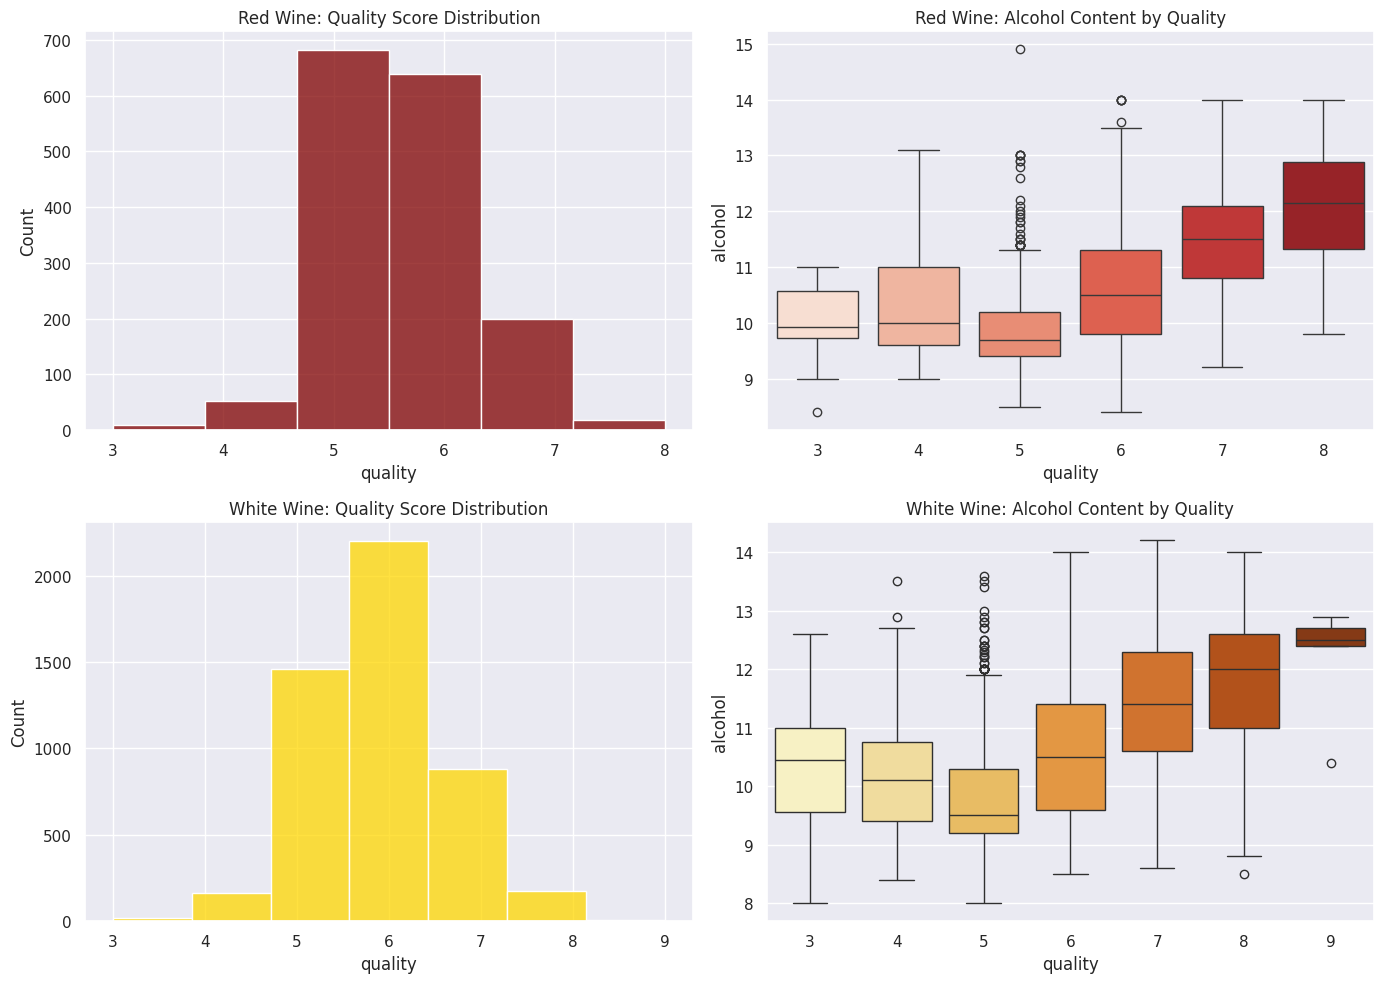

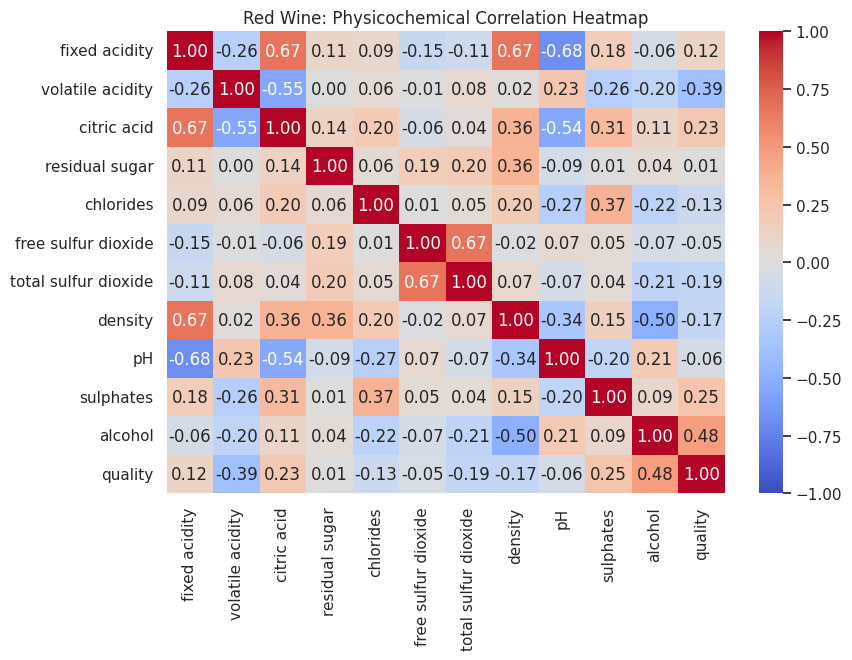

=== Top 2 Attributes Associated with Quality (Red Wine) ===
Alcohol           : 0.4762 (Positive)
Volatile acidity  : -0.3906 (Negative)
\n


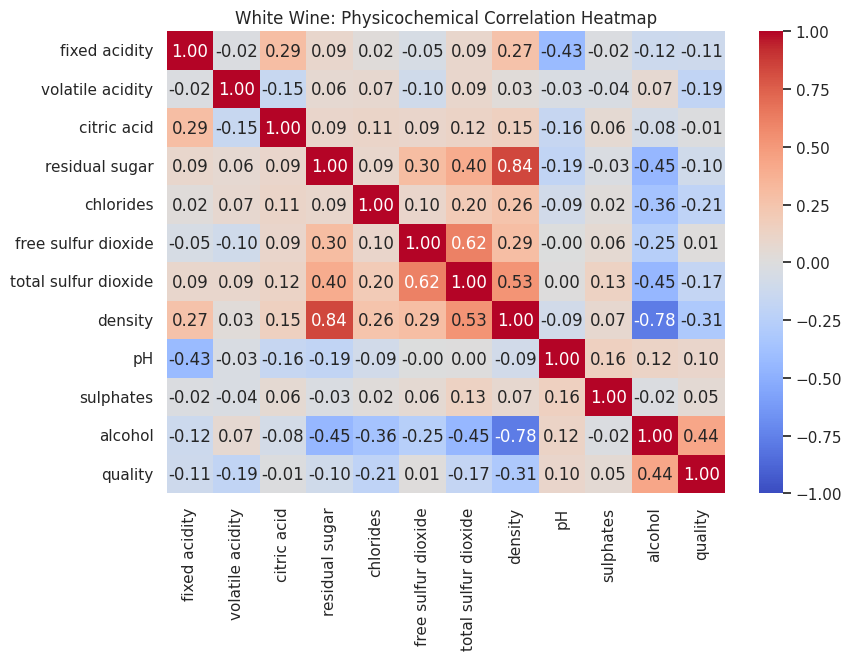

=== Top 2 Attributes Associated with Quality (White Wine) ===
Alcohol           : 0.4356 (Positive)
Density           : -0.3071 (Negative)
\n


In [15]:
# Task 2a & 2b: Histograms and Boxplots side-by-side
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Red Wine Plots
sns.histplot(df_red['quality'], bins=6, kde=False, color='maroon', ax=axes[0, 0])
axes[0, 0].set_title('Red Wine: Quality Score Distribution')
sns.boxplot(x='quality', y='alcohol', data=df_red, palette='Reds', ax=axes[0, 1])
axes[0, 1].set_title('Red Wine: Alcohol Content by Quality')

# White Wine Plots
sns.histplot(df_white['quality'], bins=7, kde=False, color='gold', ax=axes[1, 0])
axes[1, 0].set_title('White Wine: Quality Score Distribution')
sns.boxplot(x='quality', y='alcohol', data=df_white, palette='YlOrBr', ax=axes[1, 1])
axes[1, 1].set_title('White Wine: Alcohol Content by Quality')

plt.tight_layout()
plt.show()

# Task 2c & 2d: Correlation Heatmaps & Top Attributes
for name, df in wines.items():
    plt.figure(figsize=(9, 6))
    sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
    plt.title(f'{name}: Physicochemical Correlation Heatmap')
    plt.show()

    correlations = df.corr()['quality'].drop('quality')
    top_2 = correlations.abs().sort_values(ascending=False).head(2)
    print(f"=== Top 2 Attributes Associated with Quality ({name}) ===")
    for attr in top_2.index:
        direction = "Positive" if correlations[attr] > 0 else "Negative"
        print(f"{attr.capitalize():<18}: {correlations[attr]:.4f} ({direction})")
    print("\\n")

For both datasets, most of the wine quality scores sit right in the middle at 5 or 6. The box plots show that wines with scores of 7 and 8 usually have more alcohol. From the heatmaps, alcohol and volatile acidity are the strongest factors for red wine, while alcohol and density matter most for white wine.

=== MULTIPLE LINEAR REGRESSION EVALUATION ===
\n[Red Wine Test Metrics]
MAE: 0.504 | MSE: 0.390 | RMSE: 0.625 | R-Squared: 0.403
Top 2 Influential Predictors:
  - Alcohol           : 0.2966
  - Volatile acidity  : -0.1794


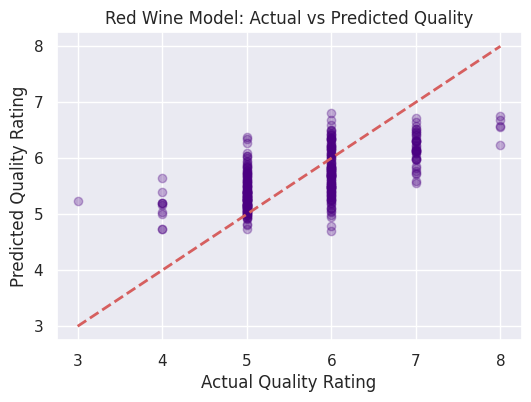

\n[White Wine Test Metrics]
MAE: 0.586 | MSE: 0.569 | RMSE: 0.754 | R-Squared: 0.265
Top 2 Influential Predictors:
  - Density           : -0.3754
  - Residual sugar    : 0.3661


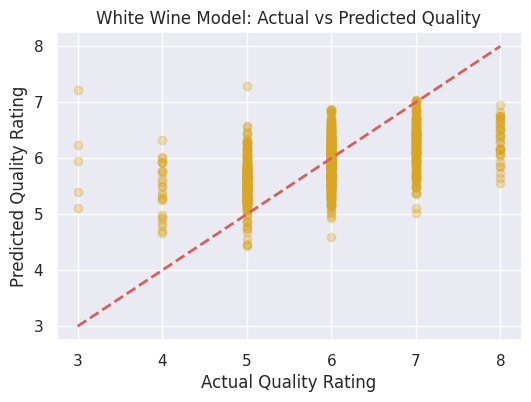

In [16]:
print("=== MULTIPLE LINEAR REGRESSION EVALUATION ===")

for name, df in wines.items():
    # Split Features and Target
    X = df.drop('quality', axis=1)
    y = df['quality']

    # Task 3b: 80/20 Train-Test Split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Standardize features for accurate regression coefficient extraction
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Task 3a: Train Linear Regression Model
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    # Task 3c: Metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f"\\n[{name} Test Metrics]")
    print(f"MAE: {mae:.3f} | MSE: {mse:.3f} | RMSE: {rmse:.3f} | R-Squared: {r2:.3f}")

    # Task 3d: Feature Importance (Standardized Coefficients)
    std_coeffs = pd.Series(model.coef_, index=X.columns)
    top_2_coeffs = std_coeffs.abs().sort_values(ascending=False).head(2)
    print("Top 2 Influential Predictors:")
    for attr in top_2_coeffs.index:
        print(f"  - {attr.capitalize():<18}: {std_coeffs[attr]:.4f}")

    # Task 3e: Scatter Plot (Actual vs Predicted)
    plt.figure(figsize=(6, 4))
    plt.scatter(y_test, y_pred, alpha=0.3, color='indigo' if 'Red' in name else 'goldenrod')
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    plt.title(f'{name} Model: Actual vs Predicted Quality')
    plt.xlabel('Actual Quality Rating')
    plt.ylabel('Predicted Quality Rating')
    plt.show()

Based on the regression coefficients, alcohol and volatile acidity are the biggest predictors for red wine. For white wine, it's density and residual sugar, but those two are highly correlated with each other, so the white wine model's weights might be slightly skewed.

The scatter plots show that the models mostly just guess scores of 5 or 6 and miss the really good or bad wines. Because the data is so imbalanced, basic linear regression doesn't capture the complex chemistry of wine tasting.

Ultimately, if the lab wants to screen wines, they should look at alcohol, volatile acidity, and density. But these models aren't accurate enough to replace human tasters yet. The R-squared values are pretty low, and the error margin is too high for a 10-point scale.

# Final Project Conclusion

To wrap up the airlines case study, the unsupervised learning models showed that passenger behavior can be distinctly grouped, but picking the right algorithm is crucial. K-Means and Hierarchical clustering both optimized well at 4 clusters and gave us segments that make actual business sense. We found that while the vast majority of users are just casual flyers, there is a highly profitable subset of customers who rack up massive miles through co-branded credit cards without actually flying much. There is also a tiny fraction of elite, high-frequency "road warriors". DBSCAN, on the other hand, wasn't great for marketing segmentation because it grouped almost everyone together and only separated out the extreme outliers, though this proves it would be great for anomaly detection. From a business perspective, the airline can use the K-Means clusters to send targeted flight promos to the credit-card users to get them to actually book seats, while giving automatic loyalty upgrades to the elite flyers to retain them.

For the wine quality case study, the goal was to see if objective chemical lab tests could completely replace human taste testers. I chose to build separate multiple linear regression models for red and white wines because combining them without adding a categorical 'wine type' indicator would confuse the algorithm due to their totally different chemical baselines. After running the models, it's clear that alcohol content is the most reliable positive indicator of a good wine across the board. Conversely, volatile acidity hurts red wine ratings, and high density negatively impacts white wine ratings.

However, the regression models ultimately aren't reliable enough to replace human sensory testers just yet. The red wine model only explained about 40.3% of the variance, and the white wine model was even worse at 26.5%. Because the dataset was so imbalanced (mostly just average wines scoring 5 or 6), the linear regression just guessed the average scores most of the time and completely failed to identify the really excellent or terrible wines. The models also had an RMSE of over 0.6, meaning they frequently miss the true quality by nearly a full point on a 10-point scale. The chemistry of taste seems to be too complex and non-linear for a basic multiple linear regression model to capture perfectly, so human tasters are still required for final grading.